# SoftSEEPS with WeatherBench 2 data

SoftSEEPS needs, for the valid time of every forecast, two climatological fields on the forecast grid:
`p1` (probability of a dry day) and `t2` (light/heavy threshold). This notebook shows how to take them from the
public [WeatherBench 2](https://weatherbench2.readthedocs.io/en/latest/data-guide.html) ERA5 climatology and
use them to score an IFS HRES forecast against ERA5. No account is needed; only one valid time is downloaded.

Requirements: `pip install ".[example]"` from the repository root.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr

import sys
sys.path.insert(0, "..")   # use softseeps from this repository; not needed after `pip install`
from softseeps import soft_seeps

# WeatherBench 2 provides the same data at other resolutions (e.g. 240x121, 64x32), see the data guide.
WB2 = "gs://weatherbench2/datasets"
CLIMATOLOGY = f"{WB2}/era5-hourly-climatology/1990-2019_6h_1440x721.zarr"
ERA5 = f"{WB2}/era5/1959-2023_01_10-wb13-6h-1440x721_with_derived_variables.zarr"
HRES = f"{WB2}/hres/2016-2022-0012-1440x721.zarr"

def open_zarr(path):
    return xr.open_zarr(path, storage_options={"token": "anon"}, decode_timedelta=True)

## Forecast, observation and climatology

24 h precipitation over the first forecast day. The climatology is selected for the **day of year and hour of the
valid time** and must be on the same grid as the forecast. WeatherBench 2 stores precipitation in metres; everything
is converted to mm, the unit of `dry_threshold` and `tau`.

In [2]:
init = pd.Timestamp("2020-07-01T00")
valid = init + pd.Timedelta(hours=24)
var = "total_precipitation_24hr"
dry_threshold = 0.25   # mm; WeatherBench 2 uses 0.1 mm for 6 h accumulations

forecast = open_zarr(HRES)[var].sel(time=init, prediction_timedelta=pd.Timedelta(hours=24))
observation = open_zarr(ERA5)[var].sel(time=valid)
clim = open_zarr(CLIMATOLOGY).sel(dayofyear=valid.dayofyear, hour=valid.hour)
p1 = clim[f"{var}_seeps_dry_fraction"]
t2 = clim[f"{var}_seeps_threshold"]

def to_tensor(x, scale=1.0):   # same (latitude, longitude) order for all fields
    x = x.sortby("latitude").sortby("longitude").transpose("latitude", "longitude")
    return torch.tensor(x.values * scale, dtype=torch.float32)

forecast = to_tensor(forecast, 1000).clamp(min=0)
observation = to_tensor(observation, 1000)
p1, t2 = to_tensor(p1), to_tensor(t2, 1000)
weights = torch.cos(torch.deg2rad(torch.tensor(np.sort(clim.latitude.values))))[:, None]   # area weights
print(forecast.shape, p1.shape, t2.shape)

torch.Size([721, 1440]) torch.Size([721, 1440]) torch.Size([721, 1440])


## The smoothing parameter τ

Large τ blurs the category boundaries; τ → 0 gives the discrete SEEPS.

tau = 10     SoftSEEPS = 0.8638
tau = 5      SoftSEEPS = 0.7955
tau = 2      SoftSEEPS = 0.6778
tau = 1      SoftSEEPS = 0.5837
tau = 0.5    SoftSEEPS = 0.5020
tau = 0.2    SoftSEEPS = 0.4143
tau = 0.1    SoftSEEPS = 0.3594
tau = 0.05   SoftSEEPS = 0.3282
tau = 0.01   SoftSEEPS = 0.3173
tau = 0.001  SoftSEEPS = 0.3169


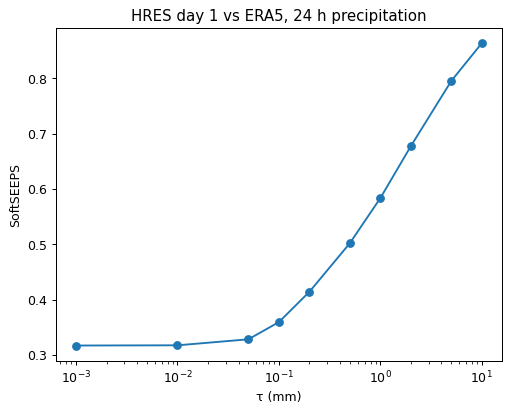

In [3]:
taus = [10, 5, 2, 1, 0.5, 0.2, 0.1, 0.05, 0.01, 0.001]
scores = [soft_seeps(forecast, observation, p1, t2, dry_threshold, tau, weights).item() for tau in taus]
for tau, s in zip(taus, scores):
    print(f"tau = {tau:<6g} SoftSEEPS = {s:.4f}")

plt.semilogx(taus, scores, "o-")
plt.xlabel("τ (mm)"); plt.ylabel("SoftSEEPS"); plt.title("HRES day 1 vs ERA5, 24 h precipitation")
plt.show()

## As a training loss

SoftSEEPS is differentiable in the forecast. In training, look up `p1` and `t2` for the valid time of each sample
(as above) and add it to e.g. an MSLE loss:

```python
loss = msle(pred, obs) + lam * soft_seeps(pred, obs, p1, t2, dry_threshold, tau, weights)
```

The gradient shows where the forecast would need more (blue) or less (red) rain:

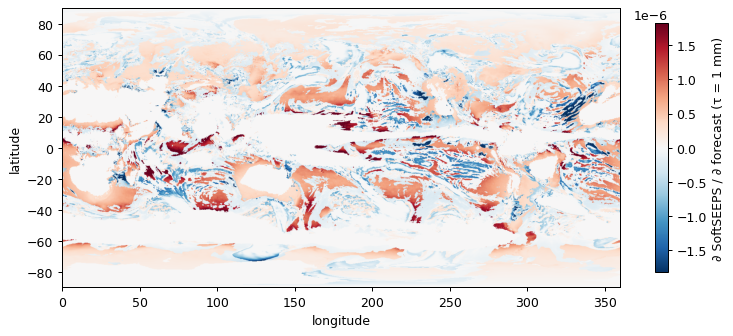

In [4]:
x = forecast.clone().requires_grad_(True)
soft_seeps(x, observation, p1, t2, dry_threshold, tau=1.0, weights=weights).backward()
g = x.grad.numpy()
v = np.percentile(np.abs(g[g != 0]), 99)
plt.figure(figsize=(10, 4.5))
plt.imshow(g, origin="lower", extent=(0, 360, -90, 90), cmap="RdBu_r", vmin=-v, vmax=v)
plt.colorbar(label="∂ SoftSEEPS / ∂ forecast (τ = 1 mm)", shrink=0.8)
plt.xlabel("longitude"); plt.ylabel("latitude")
plt.show()